# 03 — Preparação dos dados: EdNet-KT3

**CRISP-DM, fase 3** · corresponde às seções **§5.2 e §5.3** de `docs/DOCUMENTACAO.md`

O KT3 tem 297.915 arquivos (um por estudante) e 89 milhões de linhas. A preparação transforma **cada arquivo** em **uma linha de atributos por estudante**. Neste notebook:

1. Mostramos **todo o tratamento num estudante**, passo a passo, e conferimos com o extrator oficial (`src/ednet_01_extract.py`)
2. Aplicamos o mesmo tratamento à base inteira (opcional; leva cerca de 8 minutos) ou carregamos o resultado já processado
3. Mostramos o relatório de qualidade (nulos, duplicadas, inválidos) e as bases de análise de cada pergunta
4. Normalização e transformações (§5.3)

> Se o EdNet bruto não estiver nesta máquina (ver o notebook 01, seção 5), as células de demonstração avisam e o resto usa `data/processed/ednet_users.csv.gz`.

In [1]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
import io, re
import ednet_01_extract as X
print("EdNet bruto disponível:", C.EDNET_BRUTO_DISPONIVEL, "|", C.EDNET_KT3)
if C.EDNET_BRUTO_DISPONIVEL:
    X._init()   # carrega o gabarito (questions.csv)

Projeto: C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready
EdNet bruto disponível: False | None


## 1. Um estudante, passo a passo

Estudante de exemplo: **u10276** (377 eventos, diagnóstico + prática + explicações + aulas, e respostas trocadas antes de enviar).

### 1.1 Leitura e nulos

In [2]:
UID = "u10276"
if C.EDNET_BRUTO_DISPONIVEL:
    df = X.ler_estudante(UID)
    print("Linhas brutas:", len(df))
    print("Nulos por coluna:", df.isna().sum().to_dict())
    display(df.head(12))
else:
    print("EdNet bruto não disponível — pule para a seção 2.")

EdNet bruto não disponível — pule para a seção 2.


`user_answer` só existe nas ações `respond`. Os nulos nas outras ações são **esperados** e não indicam dado faltando:

In [3]:
if C.EDNET_BRUTO_DISPONIVEL:
    display(pd.crosstab(df["action_type"], df["user_answer"].isna().map({True: "user_answer vazio", False: "preenchido"})))

### 1.2 Duplicadas exatas

Este estudante não tem duplicadas. Para ilustrar, o estudante **u551617** tem uma linha repetida (mesmo timestamp, ação, item, origem e plataforma):

In [4]:
if C.EDNET_BRUTO_DISPONIVEL:
    d2 = X.ler_estudante("u551617")
    display(d2[d2.duplicated(keep=False)])
    print("Duplicadas em u10276:", df.duplicated().sum())
    df = df[~df.duplicated()]

### 1.3 Validação de domínio

Cada campo é conferido contra os valores possíveis. Linhas inválidas seriam removidas e contadas. Na base inteira, **nenhuma** foi inválida.

In [5]:
if C.EDNET_BRUTO_DISPONIVEL:
    ts = pd.to_numeric(df["timestamp"], errors="coerce")
    is_resp = df["action_type"].eq("respond")
    checks = {
        "timestamp não numérico ou fora de 2017–2020": (ts.isna() | (ts < X.TS_MIN) | (ts > X.TS_MAX)).sum(),
        "action_type fora de {enter, respond, submit, quit}": (~df["action_type"].isin(X.VALID_ACTIONS)).sum(),
        "item_id fora do padrão [q|b|e|l]+número": (~df["item_id"].fillna("").str.match(X.ITEM_RE)).sum(),
        "platform fora de {mobile, web}": (~df["platform"].isin(X.VALID_PLATFORMS)).sum(),
        "respond sem resposta a–d": (is_resp & ~df["user_answer"].isin(X.VALID_ANSWERS)).sum(),
        "respond que não é sobre questão (q…)": (is_resp & ~df["item_id"].str.startswith("q")).sum(),
    }
    display(pd.Series(checks, name="linhas inválidas").to_frame())
    df["timestamp"] = ts.astype("int64")
    print("Arquivo já estava em ordem cronológica:", df["timestamp"].is_monotonic_increasing)
    df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)

### 1.4 Sessões, dias ativos e tempo de estudo

Uma **nova sessão** começa depois de mais de 30 minutos sem eventos. O **tempo de estudo** é a soma dos intervalos dentro das sessões.

In [6]:
if C.EDNET_BRUTO_DISPONIVEL:
    t = df["timestamp"].to_numpy()
    gaps = np.diff(t)
    nova = np.concatenate([[True], gaps > X.GAP_MS])
    df["momento"] = pd.to_datetime(df["timestamp"], unit="ms")
    df["nova_sessao"] = nova
    display(df.loc[df["nova_sessao"], ["momento", "action_type", "item_id", "source"]])
    print("Sessões:", nova.sum(),
          "| dias ativos:", df["momento"].dt.normalize().nunique(),
          "| tempo de estudo (min):", round(gaps[gaps <= X.GAP_MS].sum() / 60000, 3))

### 1.5 O que o estudante fez: ações, origens e conteúdos

- **Origem (`source`)**: o contexto da atividade (diagnóstico, prática por parte, revisão…).
- **Conteúdo acessado (`enter`)**: `b` = bloco de questões, `e` = **explicação** (o feedback depois de responder), `l` = aula.

In [7]:
if C.EDNET_BRUTO_DISPONIVEL:
    print("Ações:", df["action_type"].value_counts().to_dict())
    print("Origens:", df["source"].value_counts().to_dict())
    prefixo = df["item_id"].str[0]
    print("Acessos (enter) por tipo:", df.loc[df["action_type"] == "enter", "item_id"].str[0]
          .map({"b": "questões", "e": "explicação", "l": "aula"}).value_counts().to_dict())

### 1.6 Respostas finais e correção

O estudante pode **trocar de alternativa** antes de enviar. Só conta a **última resposta de cada questão antes do `submit`**. Exemplo de questão com resposta trocada:

In [8]:
if C.EDNET_BRUTO_DISPONIVEL:
    act = df["action_type"].to_numpy()
    df["seg"] = np.concatenate([[0], np.cumsum(act[:-1] == "submit")])     # bloco entre dois submits
    enviados = set(df["seg"][act == "submit"])
    resp = df[(df["action_type"] == "respond") & df["seg"].isin(enviados)]
    trocadas = resp[resp.duplicated(["seg", "item_id"], keep=False)]
    seg_ex = trocadas["seg"].iloc[0]
    display(df[df["seg"] == seg_ex][["momento", "action_type", "item_id", "source", "user_answer"]])
    final = resp.drop_duplicates(["seg", "item_id"], keep="last")
    print(f"Respostas registradas: {len(resp)} → respostas finais: {len(final)} "
          f"({len(resp) - len(final)} intermediárias descartadas)")

Cada resposta final é comparada com o **gabarito** (`questions.csv`, coluna `correct_answer`):

In [9]:
if C.EDNET_BRUTO_DISPONIVEL:
    gabarito = pd.read_csv(C.EDNET_QUESTIONS, usecols=["question_id", "correct_answer"]).set_index("question_id")["correct_answer"]
    final = final.assign(gabarito=final["item_id"].map(gabarito))
    final["acertou"] = final["user_answer"] == final["gabarito"]
    display(final[["momento", "item_id", "source", "user_answer", "gabarito", "acertou"]].head(10))

### 1.7 Medidas de desempenho do estudante

| Medida | Definição | Usada em |
|---|---|---|
| `acuracia` | acertos / respostas finais (todas) | só descritiva |
| `acuracia_diag` | acurácia no **diagnóstico** (nivelamento inicial, ≥ 5 questões) | “pré-teste” (controle) |
| `acuracia_pos_diag` | acurácia nas questões **fora do diagnóstico** (≥ 10) | desempenho nas Q1 e Q10 |
| `acuracia_inicio_sem_diag` / `acuracia_fim_sem_diag` | primeiras 20 / últimas 20 respostas fora do diagnóstico (≥ 40) | evolução na Q5 |

O diagnóstico é **mais difícil** que a prática, e por isso ele é separado. Misturar os dois foi a causa de dois erros corrigidos nas auditorias (notebooks 04 e 06):

In [10]:
if C.EDNET_BRUTO_DISPONIVEL:
    c = final["acertou"].to_numpy()
    src = final["source"].to_numpy()
    diag, nd = c[src == "diagnosis"], c[src != "diagnosis"]
    W = C.EDNET_EVOL_WINDOW
    print(f"Respostas finais: {len(c)} | no diagnóstico: {len(diag)} | fora do diagnóstico: {len(nd)}")
    print(f"acuracia geral        = {c.mean():.4f}")
    print(f"acuracia_diag         = {diag.mean():.4f}")
    print(f"acuracia_pos_diag     = {nd.mean():.4f}")
    print(f"janela inicial (20)   = {nd[:W].mean():.4f} | janela final (20) = {nd[-W:].mean():.4f} "
          f"→ evolução = {nd[-W:].mean() - nd[:W].mean():+.4f}")
    print(f"(fórmula antiga, com diagnóstico: início {c[:W].mean():.4f}; "
          f"{(src[:W] == 'diagnosis').sum()} das 20 primeiras eram do diagnóstico)")

### 1.8 Conferência com o extrator oficial

A mesma função usada para os 297.915 estudantes (`process_user`), aplicada a este aluno, deve dar os mesmos números. Eles devem estar também no arquivo processado oficial:

In [11]:
if C.EDNET_BRUTO_DISPONIVEL:
    nome = f"KT3/{UID}.csv" if C.EDNET_KT3.is_file() else f"{UID}.csv"
    linha, qualidade = X.process_user(nome)
    oficial = pd.read_csv(C.PROCESSED / "ednet_users.csv.gz").set_index("user_id").loc[UID]
    comp = pd.DataFrame({"process_user": pd.Series(linha).drop("user_id"), "arquivo oficial": oficial}).dropna(how="all")
    comp = comp[(comp["process_user"].fillna(0) != 0) | (comp["arquivo oficial"].fillna(0) != 0)]
    display(comp)
    assert np.allclose(comp["process_user"].astype(float), comp["arquivo oficial"].astype(float), equal_nan=True)
    print("✅ O passo a passo, o extrator e o arquivo oficial dão os mesmos valores.")
    print(f"Conferência manual: n_respondidas={len(c)} | acuracia={round(c.mean(), 4)} | "
          f"inicio_sem_diag={round(nd[:W].mean(), 4)} | fim_sem_diag={round(nd[-W:].mean(), 4)}")

## 2. A base inteira

O mesmo tratamento é aplicado aos 297.915 arquivos, em paralelo, por `src/ednet_01_extract.py`. Isso leva cerca de 8 minutos e gera:
- `data/processed/ednet_users.csv.gz`: 1 linha por estudante, 48 atributos
- `outputs/tables/ednet_qualidade.json`: contagens de qualidade

Para **refazer** a extração aqui, mude `EXECUTAR_EXTRACAO` para `True`. O notebook roda o script num processo separado, porque o processamento paralelo não funciona dentro do Jupyter no Windows.

In [12]:
EXECUTAR_EXTRACAO = False

if EXECUTAR_EXTRACAO:
    import subprocess, os
    if not C.EDNET_BRUTO_DISPONIVEL:
        raise FileNotFoundError("EdNet bruto não encontrado — veja o notebook 01, seção 5.")
    r = subprocess.run([sys.executable, str(ROOT / "src" / "ednet_01_extract.py")], capture_output=True, text=True,
                       encoding="utf-8", env={**os.environ, "PYTHONUTF8": "1"})
    print(r.stdout[-1500:], r.stderr[-1500:])
else:
    print("Usando a extração já feita:", C.PROCESSED / "ednet_users.csv.gz")

Usando a extração já feita: C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready\data\processed\ednet_users.csv.gz


### 2.1 Relatório de qualidade da base inteira (§5.2)

In [13]:
qual = json.loads((C.TAB / "ednet_qualidade.json").read_text(encoding="utf-8"))
f = lambda v: f"{v:,}".replace(",", ".")
tabela = pd.DataFrame([
    ("Leitura", "linhas brutas", f(qual["linhas_brutas"])),
    ("Nulos", "timestamp / action_type / item_id / source / platform",
     " / ".join(f(qual[f"nulos_{k}"]) for k in ["timestamp", "action_type", "item_id", "source", "platform"])),
    ("Nulos", "user_answer (esperado: só respond tem resposta)", f(qual["nulos_user_answer"])),
    ("Duplicadas", "linhas exatas removidas", f(qual["duplicadas"])),
    ("Validação", "timestamp / action_type / item_id / platform / resposta inválidos",
     " / ".join(f(qual[k]) for k in ["invalido_timestamp", "invalido_action_type", "invalido_item_id",
                                       "invalido_platform", "invalido_resposta"])),
    ("Ordenação", "arquivos fora de ordem cronológica", f(qual["arquivos_fora_de_ordem"])),
    ("Base limpa", "linhas", f(qual["linhas_limpas"])),
    ("Respostas", "intermediárias descartadas (trocou de alternativa)", f(qual["respostas_intermediarias_descartadas"])),
    ("Correção", "questões sem gabarito", f(qual["questoes_sem_gabarito"])),
    ("Estudantes", "arquivos / com dados", f"{f(qual['arquivos'])} / {f(qual['usuarios_com_dados'])}"),
], columns=["etapa", "verificação", "resultado"])
tabela

,etapa,verificação,resultado
0,Leitura,linhas brutas,89.270.654
1,Nulos,timestamp / action_type / item_id / source / platform,0 / 0 / 0 / 0 / 0
2,Nulos,user_answer (esperado: só respond tem resposta),65.886.174
3,Duplicadas,linhas exatas removidas,75.778
4,Validação,timestamp / action_type / item_id / platform / resposta inválidos,0 / 0 / 0 / 0 / 0
5,Ordenação,arquivos fora de ordem cronológica,0
6,Base limpa,linhas,89.194.876
7,Respostas,intermediárias descartadas (trocou de alternativa),5.325.940
8,Correção,questões sem gabarito,0
9,Estudantes,arquivos / com dados,297.915 / 297.915


In [14]:
u = pd.read_csv(C.PROCESSED / "ednet_users.csv.gz")
print("Estudantes × atributos:", u.shape)
print("Respostas finais na base:", f(int(u["n_respondidas"].sum())))
print(f"Acurácia geral: {u['n_acertos'].sum() / u['n_respondidas'].sum():.2%}")
src_cols = [c for c in u.columns if c.startswith("src_")]
print("As origens somam exatamente o total de eventos de cada estudante:", bool((u[src_cols].sum(axis=1) == u["n_eventos"]).all()))
u[["n_eventos", "n_sessoes", "dias_ativos", "tempo_estudo_min", "n_respondidas", "acuracia"]].describe().round(2)

Estudantes × atributos: (297915, 48)
Respostas finais na base: 17.981.865
Acurácia geral: 64.84%
As origens somam exatamente o total de eventos de cada estudante: True


,n_eventos,n_sessoes,dias_ativos,tempo_estudo_min,n_respondidas,acuracia
count,297915.0,297915.00,297915.00,297915.00,297915.00,296700.00
mean,299.4,4.63,3.07,105.51,60.36,0.50
std,1427.4,17.96,8.63,604.67,284.53,0.22
min,2.0,1.00,1.00,0.00,0.00,0.00
25%,18.0,1.00,1.00,2.78,6.00,0.33
50%,27.0,1.00,1.00,4.46,8.00,0.50
75%,77.0,2.00,1.00,18.02,17.00,0.67
max,169794.0,1341.00,413.00,57024.33,31749.00,1.00


## 3. Bases de análise de cada pergunta

Cada pergunta usa o subconjunto de estudantes que tem os dados necessários. **São populações diferentes, e cada número usa o seu denominador.**

In [15]:
nd = u["n_respondidas"] - u["resp_diagnosis"]
so_diag = u["n_eventos"] == u["src_diagnosis"]
bases = pd.DataFrame([
    ("Todos", len(u), "descritiva; % que usa (Q10)"),
    ("Foram além do diagnóstico (usaram a plataforma)", int((~so_diag).sum()), "Q4; % de ativos que usa (Q10)"),
    ("≥ 10 respostas fora do diagnóstico", int((nd >= 10).sum()), "Q1"),
    ("diagnóstico ≥ 5 E ≥ 10 respostas fora dele", int(((u["resp_diagnosis"] >= 5) & (nd >= 10)).sum()), "Q1 e Q10 com controle do nível inicial"),
    ("≥ 40 respostas fora do diagnóstico", int((nd >= 40).sum()), "Q5"),
], columns=["conjunto", "estudantes", "usado em"])
bases["estudantes"] = bases["estudantes"].map(f)
bases

,conjunto,estudantes,usado em
0,Todos,297.915,descritiva; % que usa (Q10)
1,Foram além do diagnóstico (usaram a plataforma),111.748,Q4; % de ativos que usa (Q10)
2,≥ 10 respostas fora do diagnóstico,76.252,Q1
3,diagnóstico ≥ 5 E ≥ 10 respostas fora dele,66.062,Q1 e Q10 com controle do nível inicial
4,≥ 40 respostas fora do diagnóstico,42.720,Q5


In [16]:
print(f"Só fizeram o diagnóstico e nunca voltaram: {so_diag.sum():,} ({so_diag.mean():.1%})".replace(",", "."))
print(f"Tiveram uma única sessão: {(u['n_sessoes'] == 1).mean():.1%}")

Só fizeram o diagnóstico e nunca voltaram: 186.167 (62.5%)
Tiveram uma única sessão: 73.3%


## 4. Normalização e transformações (§5.3)

| Técnica | Onde | Por quê |
|---|---|---|
| **Proporção (participação %)** | Q4: eventos da atividade ÷ total do estudante | Compara perfis de estudantes com volumes muito diferentes |
| **Percentil (0–100)** | Índice de engajamento (Q4) | Põe sessões e dias na mesma escala, sem efeito de outliers |
| **Acurácia (0–1)** | Desempenho | Normaliza pelo nº de questões |
| **Escala log** | Eixos de nº de interações | Distribuição muito assimétrica |
| **Postos (Spearman)** | Todas as correlações | Não supõe normalidade nem relação linear |
| *Z-score* — **não usado** | — | Caudas longas: média e desvio dominados por poucos usuários |

Por que log e postos: a distribuição do nº de eventos por estudante.

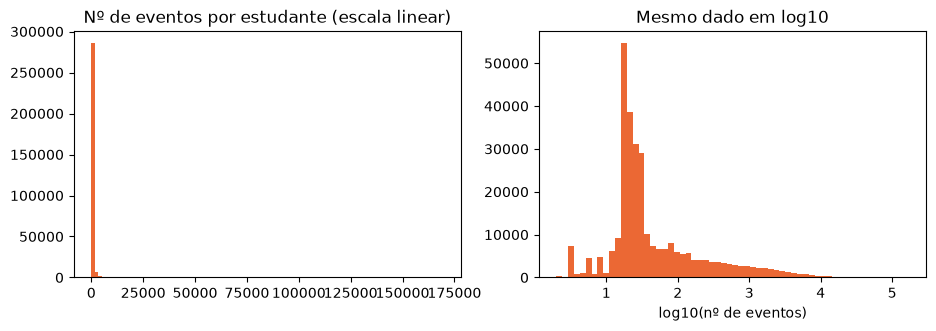

Mediana: 27 | média: 299 | máximo: 169.794


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
axs[0].hist(u["n_eventos"], bins=100, color="#eb6834")
axs[0].set_title("Nº de eventos por estudante (escala linear)")
axs[1].hist(np.log10(u["n_eventos"]), bins=60, color="#eb6834")
axs[1].set_title("Mesmo dado em log10")
axs[1].set_xlabel("log10(nº de eventos)")
plt.show()
print(f"Mediana: {u['n_eventos'].median():.0f} | média: {u['n_eventos'].mean():.0f} | máximo: {u['n_eventos'].max():,}".replace(",", "."))

**Resultado:** 297.915 estudantes processados, 89.194.876 linhas limpas e 17.981.865 respostas finais corrigidas. **62,5%** dos estudantes só fizeram o diagnóstico inicial.

**Próximo:** `04_Q1_interacao_desempenho.ipynb`.